In [1]:
!pip install pandas numpy pyarrow

   ---------------------------------------- 0.0/28.5 MB ? eta -:--:--
   -- ------------------------------------- 1.6/28.5 MB 12.7 MB/s eta 0:00:03
   -------- ------------------------------- 6.0/28.5 MB 18.4 MB/s eta 0:00:02
   --------------- ------------------------ 11.0/28.5 MB 19.9 MB/s eta 0:00:01
   --------------------- ------------------ 15.2/28.5 MB 20.9 MB/s eta 0:00:01
   ----------------------------- ---------- 21.0/28.5 MB 21.3 MB/s eta 0:00:01
   --------------------------------- ------ 23.6/28.5 MB 19.7 MB/s eta 0:00:01
   ------------------------------------- -- 27.0/28.5 MB 19.1 MB/s eta 0:00:01
   ---------------------------------------- 28.5/28.5 MB 17.8 MB/s  0:00:01


In [6]:
import pandas as pd
import numpy as np
import os

In [11]:
import os

print(os.getcwd())
print(os.listdir())

C:\Users\eswar\MLOPS
['.ipynb_checkpoints', 'Exp_2.ipynb', 'Exp_3.ipynb', 'smart_campus_energy.csv']


In [12]:
df = pd.read_csv("smart_campus_energy.csv")

print("Dataset loaded successfully!")

df.head()

Dataset loaded successfully!


,timestamp,building_id,room_type,occupancy,temperature,humidity,co2_level,hvac_status,lighting_status,outdoor_temperature,energy_kwh,high_energy_usage
0,2025-01-01 00:00:00,B3,Lab,0,28.54,69.07,380.0,0,0,26.83,1.867,0
1,2025-01-01 01:00:00,B2,Library,0,30.94,79.02,380.0,0,0,28.85,2.667,0
2,2025-01-01 02:00:00,B4,Library,0,29.72,69.97,380.0,0,0,28.84,3.121,0
3,2025-01-01 03:00:00,B3,Office,0,29.89,67.74,393.2,1,0,26.93,2.883,0
4,2025-01-01 04:00:00,B1,Library,0,25.42,60.30,594.2,1,0,25.72,2.716,0


In [13]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

Dataset Shape: (2400, 12)

Column Names:
Index(['timestamp', 'building_id', 'room_type', 'occupancy', 'temperature',
       'humidity', 'co2_level', 'hvac_status', 'lighting_status',
       'outdoor_temperature', 'energy_kwh', 'high_energy_usage'],
      dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 2400 entries, 0 to 2399
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   timestamp            2400 non-null   str    
 1   building_id          2400 non-null   str    
 2   room_type            2400 non-null   str    
 3   occupancy            2400 non-null   int64  
 4   temperature          2371 non-null   float64
 5   humidity             2371 non-null   float64
 6   co2_level            2371 non-null   float64
 7   hvac_status          2400 non-null   int64  
 8   lighting_status      2400 non-null   int64  
 9   outdoor_temperature  2400 non-null   float64
 10  energy_kw

In [14]:
df["timestamp"] = pd.to_datetime(
    df["timestamp"]
)

print(df["timestamp"].dtype)

datetime64[us]


In [15]:
df["hour"] = df["timestamp"].dt.hour

In [16]:
df["day_of_week"] = (
    df["timestamp"].dt.dayofweek
)

C:\Users\eswar\AppData\Local\Temp\ipykernel_6784\2778128895.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["timestamp"].dt.dayofweek


In [17]:
df["is_weekend"] = (
    df["day_of_week"] >= 5
).astype(int)

In [18]:
df["occupancy_per_co2"] = (
    df["occupancy"] /
    df["co2_level"].clip(lower=1)
)

In [19]:
df["thermal_gap"] = abs(
    df["temperature"] -
    df["outdoor_temperature"]
)

In [20]:
df["hvac_occupancy_interaction"] = (
    df["hvac_status"] *
    df["occupancy"]
)

In [21]:
new_features = [
    "hour",
    "day_of_week",
    "is_weekend",
    "occupancy_per_co2",
    "thermal_gap",
    "hvac_occupancy_interaction"
]

df[new_features].head(10)

,hour,day_of_week,is_weekend,occupancy_per_co2,thermal_gap,hvac_occupancy_interaction
0,0,2,0,0.000000,1.71,0
1,1,2,0,0.000000,2.09,0
2,2,2,0,0.000000,0.88,0
3,3,2,0,0.000000,2.96,0
4,4,2,0,0.000000,0.30,0
5,5,2,0,0.000000,0.31,0
6,6,2,0,0.000000,2.61,0
7,7,2,0,0.000000,0.77,0
8,8,2,0,0.032438,3.40,32
9,9,2,0,0.025492,1.77,14


In [22]:
building_features = df.groupby(
    "building_id"
).agg(
    avg_occupancy=("occupancy", "mean"),
    avg_energy=("energy_kwh", "mean"),
    max_co2=("co2_level", "max"),
    hvac_usage_rate=("hvac_status", "mean")
).reset_index()

building_features

,building_id,avg_occupancy,avg_energy,max_co2,hvac_usage_rate
0,B1,8.417092,4.386518,1196.3,0.681122
1,B2,9.523031,5.296357,1208.8,0.689450
2,B3,9.040486,3.796389,1307.1,0.657895
3,B4,8.347439,5.697949,1214.3,0.679287


In [23]:
hourly_features = df.groupby(
    "hour"
).agg(
    mean_energy_by_hour=("energy_kwh", "mean"),
    mean_occupancy_by_hour=("occupancy", "mean")
).reset_index()

hourly_features

,hour,mean_energy_by_hour,mean_occupancy_by_hour
0,0,4.41188,3.34
1,1,4.55801,3.10
2,2,4.59211,3.27
3,3,4.77436,3.69
4,4,4.52431,3.00
5,5,4.47886,3.14
6,6,4.38503,3.35
7,7,4.57662,3.60
8,8,4.98126,15.88
9,9,5.31998,17.21


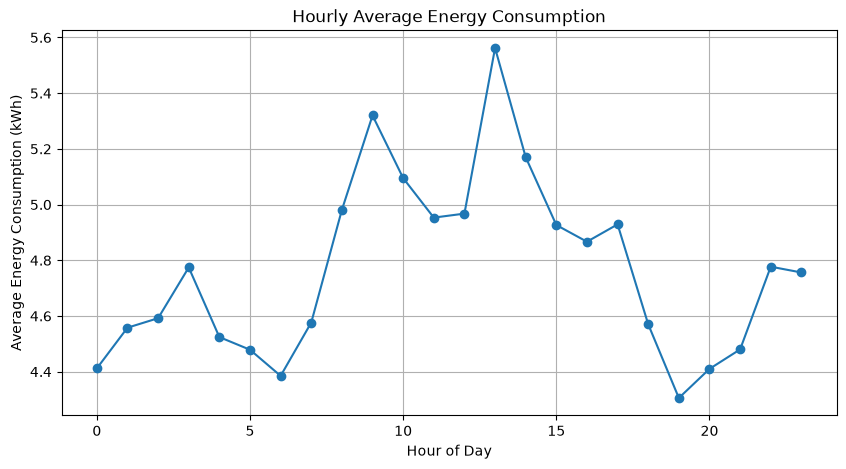

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.plot(
    hourly_features["hour"],
    hourly_features["mean_energy_by_hour"],
    marker="o"
)

plt.xlabel("Hour of Day")
plt.ylabel("Average Energy Consumption (kWh)")
plt.title("Hourly Average Energy Consumption")

plt.grid(True)
plt.show()

In [26]:
os.makedirs(
    "feature_store",
    exist_ok=True
)

print("Feature store directory created!")

Feature store directory created!


In [27]:
df.to_parquet(
    "feature_store/engineered_features.parquet",
    index=False
)

print("Engineered features stored successfully!")

Engineered features stored successfully!


In [28]:
building_features.to_csv(
    "feature_store/building_features.csv",
    index=False
)

In [29]:
hourly_features.to_csv(
    "feature_store/hourly_features.csv",
    index=False
)

print("All features stored successfully!")

All features stored successfully!


In [30]:
retrieved_features = pd.read_parquet(
    "feature_store/engineered_features.parquet"
)

retrieved_features.head()

,timestamp,building_id,room_type,occupancy,temperature,humidity,co2_level,hvac_status,lighting_status,outdoor_temperature,energy_kwh,high_energy_usage,hour,day_of_week,is_weekend,occupancy_per_co2,thermal_gap,hvac_occupancy_interaction
0,2025-01-01 00:00:00,B3,Lab,0,28.54,69.07,380.0,0,0,26.83,1.867,0,0,2,0,0.0,1.71,0
1,2025-01-01 01:00:00,B2,Library,0,30.94,79.02,380.0,0,0,28.85,2.667,0,1,2,0,0.0,2.09,0
2,2025-01-01 02:00:00,B4,Library,0,29.72,69.97,380.0,0,0,28.84,3.121,0,2,2,0,0.0,0.88,0
3,2025-01-01 03:00:00,B3,Office,0,29.89,67.74,393.2,1,0,26.93,2.883,0,3,2,0,0.0,2.96,0
4,2025-01-01 04:00:00,B1,Library,0,25.42,60.30,594.2,1,0,25.72,2.716,0,4,2,0,0.0,0.30,0


In [31]:
retrieved_building = pd.read_csv(
    "feature_store/building_features.csv"
)

retrieved_building

,building_id,avg_occupancy,avg_energy,max_co2,hvac_usage_rate
0,B1,8.417092,4.386518,1196.3,0.681122
1,B2,9.523031,5.296357,1208.8,0.689450
2,B3,9.040486,3.796389,1307.1,0.657895
3,B4,8.347439,5.697949,1214.3,0.679287


In [32]:
reused_features = retrieved_features.merge(
    retrieved_building,
    on="building_id",
    how="left"
)

reused_features.head()

,timestamp,building_id,room_type,occupancy,temperature,humidity,co2_level,hvac_status,lighting_status,outdoor_temperature,...,hour,day_of_week,is_weekend,occupancy_per_co2,thermal_gap,hvac_occupancy_interaction,avg_occupancy,avg_energy,max_co2,hvac_usage_rate
0,2025-01-01 00:00:00,B3,Lab,0,28.54,69.07,380.0,0,0,26.83,...,0,2,0,0.0,1.71,0,9.040486,3.796389,1307.1,0.657895
1,2025-01-01 01:00:00,B2,Library,0,30.94,79.02,380.0,0,0,28.85,...,1,2,0,0.0,2.09,0,9.523031,5.296357,1208.8,0.689450
2,2025-01-01 02:00:00,B4,Library,0,29.72,69.97,380.0,0,0,28.84,...,2,2,0,0.0,0.88,0,8.347439,5.697949,1214.3,0.679287
3,2025-01-01 03:00:00,B3,Office,0,29.89,67.74,393.2,1,0,26.93,...,3,2,0,0.0,2.96,0,9.040486,3.796389,1307.1,0.657895
4,2025-01-01 04:00:00,B1,Library,0,25.42,60.30,594.2,1,0,25.72,...,4,2,0,0.0,0.30,0,8.417092,4.386518,1196.3,0.681122


In [33]:
reused_features.to_csv(
    "feature_store/retrieved_features.csv",
    index=False
)

print("Retrieved features reused and saved successfully!")

Retrieved features reused and saved successfully!
